# 01 — فحص وتجهيز الداتا (LEVIR-CD+)

الهدف: تنزيل الداتا عبر `kagglehub`، اكتشاف البنية **بدون افتراض أسماء المجلدات**،
مطابقة صور الزمنين والأقنعة بالمعرف المشترك، فحص الأبعاد/القنوات/القيم،
وإحصاءات التقسيم 70/15/15، ثم عرض عينات بصرية.

المنطق الفعلي موجود في `src/data_discovery.py` و`src/config.py` — هذا الدفتر
واجهة تفاعلية له. (البديل غير التفاعلي: `python explore_data.py`)

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():   # kernel cwd may be notebooks/
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from src import config
from src.data_discovery import (build_samples, change_ratio_stats, download_dataset,
                                load_mask, print_tree, split_report, verify_samples)

config.ensure_dirs()
print("project root:", PROJECT_ROOT)

project root: D:\DEPI Project


In [2]:
root = download_dataset()
print_tree(root)

[data] Downloading / locating dataset 'mdrifaturrahman33/levir-cd-change-detection' ...
[data] kagglehub cache: D:\DEPI Project\.kagglehub_cache


[data] Dataset root: D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1

[data] Directory tree of: D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1
1/  [0 files | 1 subdirs]
    LEVIR-CD+/  [0 files | 2 subdirs]
        test/  [0 files | 3 subdirs]
        train/  [0 files | 3 subdirs]
            A/  [348 files | 0 subdirs | .png: 348]
                train_638.png
                train_639.png
                train_640.png
                ... and 345 more
            B/  [348 files | 0 subdirs | .png: 348]
                train_638.png
                train_639.png
                train_640.png
                ... and 345 more
            label/  [348 files | 0 subdirs | .png: 348]
                train_638.png
                train_639.png
                train_640.png
                ... and 345 more
            A/  [637 files | 0 subdirs | .png: 637]
                train_1.png
          

            label/  [637 files | 0 subdirs | .png: 637]
                train_1.png
                train_10.png
                train_100.png
                ... and 634 more


## اكتشاف المجلدات ومطابقة العينات

التصنيف يعتمد كلمات مفتاحية (A/B, image1/image2, mask/label ...) ويطابق الملفات
بجذور الأسماء (file stem). إن فشل الاكتشاف توقف الكود برسالة واضحة، ويمكن
تعبئة `OVERRIDES` في `src/data_discovery.py` يدويًا.

In [3]:
samples, notes = build_samples(root)
print(f"Total matched samples: {len(samples)}")
for s in samples[:5]:
    print("  e.g.", s.stem, "|", s.split, "|", s.a_path.name, s.b_path.name, s.mask_path.name)
print("\nAssumptions / notes:")
for n in notes:
    print("  -", n)


[data] Detected role folders:
    [   A] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\test\A
    [   B] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\test\B
    [mask] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\test\label
    [   A] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\train\A
    [   B] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\train\B
    [mask] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\train\label


Total matched samples: 985
  e.g. train_10 | train | train_10.png train_10.png train_10.png
  e.g. train_100 | train | train_100.png train_100.png train_100.png
  e.g. train_102 | train | train_102.png train_102.png train_102.png
  e.g. train_103 | train | train_103.png train_103.png train_103.png
  e.g. train_106 | train | train_106.png train_106.png train_106.png

Assumptions / notes:
  - Official splits absent or incomplete -- all samples will be pooled and (if needed) re-split 70/15/15 with a fixed seed.
  - Official splits incomplete (found {'train': 637, 'val': 0, 'test': 348}) -- pooling ALL samples and re-splitting 70%/15%/15% with seed=42.
  - Re-split sizes: train=689, val=147, test=149 (seed=42).
  - Leakage check passed: no sample id appears in two splits.


In [4]:
ver = verify_samples(samples)
print("image sizes :", ver["sizes"])
print("image modes :", ver["image_modes"])
print("mask values :", ver["mask_unique_values"])
print("problems    :", ver["problems"] or "none")

image sizes : {(1024, 1024): 31}
image modes : {'RGB': 31}
mask values : [0, 1]
problems    : none


In [5]:
report = split_report(samples)
print(f"{'split':>6} | {'n':>5} | {'changed%':>9} | {'unchanged%':>10} | empty masks")
for split, st in report.items():
    print(f"{split:>6} | {st['n_samples']:5d} | {st['changed_frac_mean']*100:8.2f}% | "
          f"{st['unchanged_frac_mean']*100:9.2f}% | {st['empty_masks']}/{st['n_masks']}")

 split |     n |  changed% | unchanged% | empty masks
 train |   689 |     4.17% |     95.83% | 19/300
   val |   147 |     4.59% |     95.41% | 11/147
  test |   149 |     4.34% |     95.66% | 12/149


## عينات بصرية

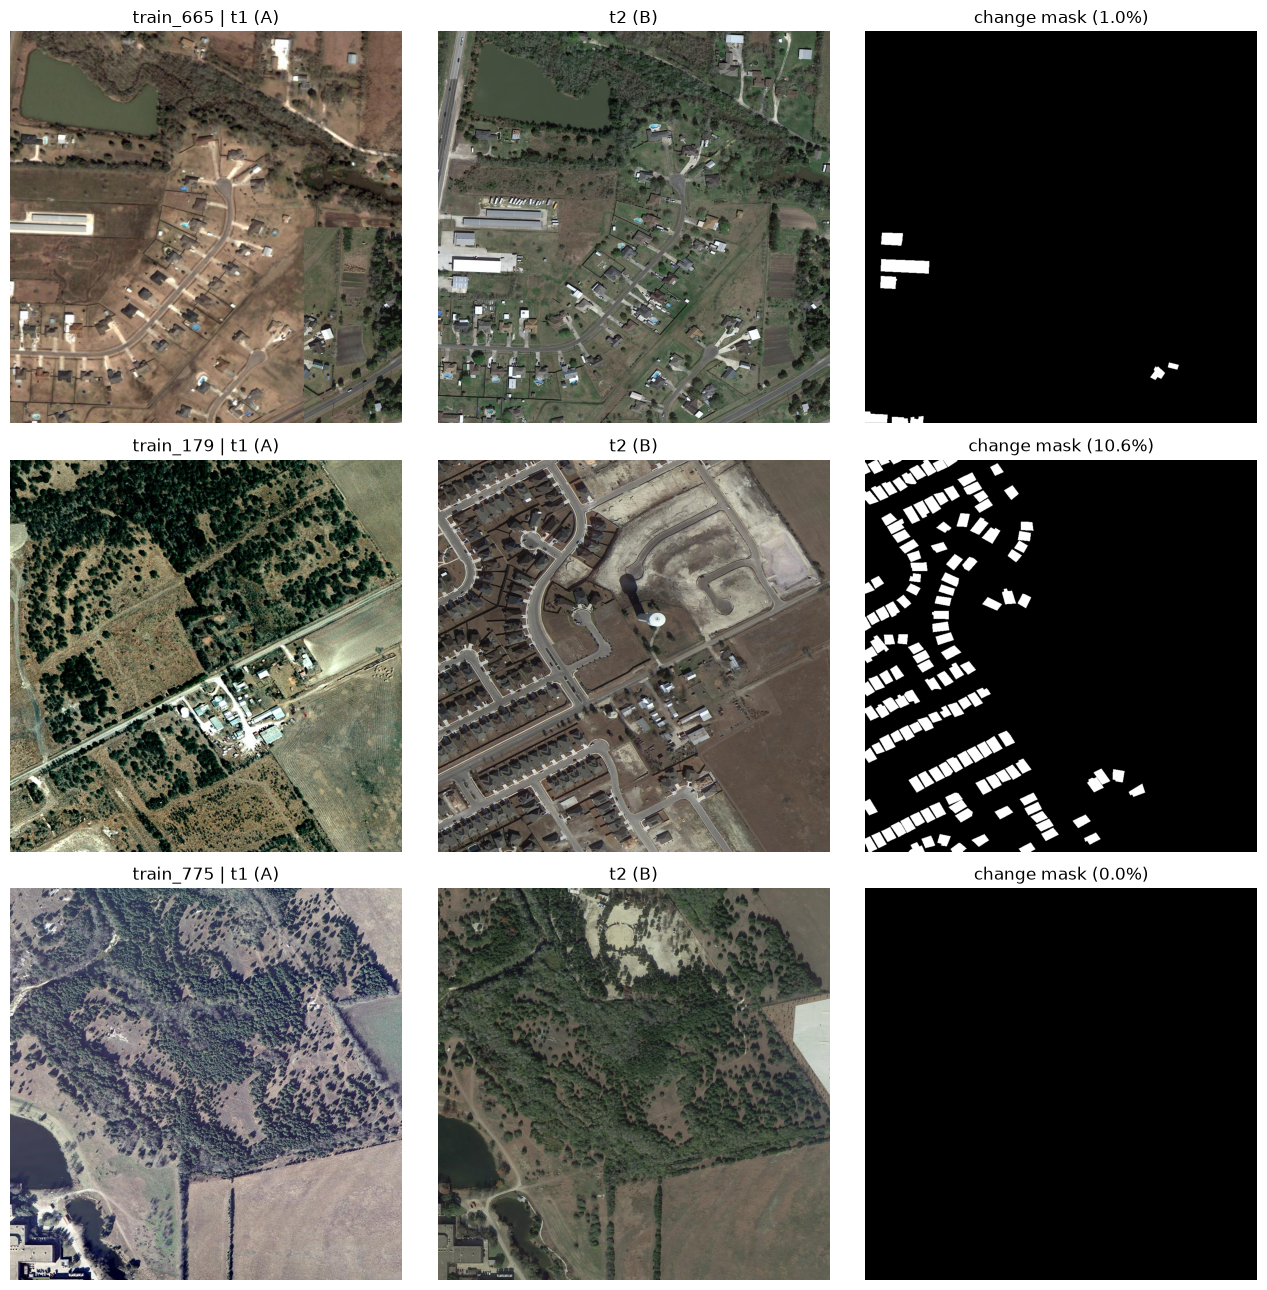

In [6]:
rng = np.random.default_rng(config.SEED)
train_samples = [s for s in samples if s.split == "train"]
picks = rng.choice(len(train_samples), size=3, replace=False)

fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for row, idx in enumerate(picks):
    s = train_samples[int(idx)]
    a = np.array(Image.open(s.a_path).convert("RGB"))
    b = np.array(Image.open(s.b_path).convert("RGB"))
    m = load_mask(s.mask_path)
    axes[row, 0].imshow(a); axes[row, 0].set_title(f"{s.stem} | t1 (A)")
    axes[row, 1].imshow(b); axes[row, 1].set_title("t2 (B)")
    axes[row, 2].imshow(m, cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title(f"change mask ({m.mean()*100:.1f}%)")
    for c in range(3):
        axes[row, c].axis("off")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "data_samples.png", dpi=110)
plt.show()

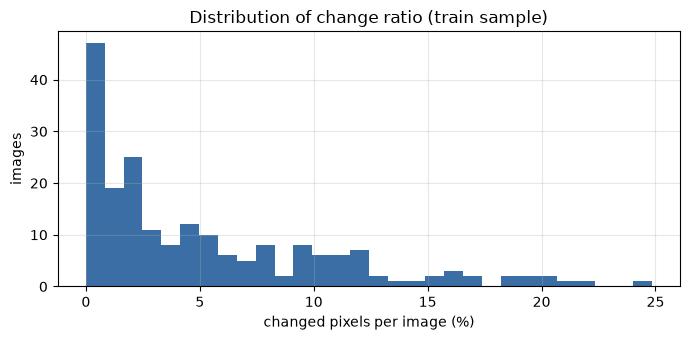

In [7]:
# توزيع نسبة التغيّر لكل عينة (على عينة من 200 قناع)
r = [load_mask(s.mask_path).mean() for s in train_samples[:200]]
plt.figure(figsize=(7, 3.5))
plt.hist(np.array(r) * 100, bins=30, color="#3b6ea5")
plt.xlabel("changed pixels per image (%)")
plt.ylabel("images")
plt.title("Distribution of change ratio (train sample)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()